In [1]:
   import pandas as pd
   from pathlib import Path

   DATA = Path("../../data/raw/olist")

   orders = pd.read_csv(DATA / "olist_orders_dataset.csv")
   orders.shape

(99441, 8)

In [2]:
   orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
 orders.dtypes

order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [6]:
date_columns = [
       "order_purchase_timestamp",
       "order_approved_at",
       "order_delivered_carrier_date",
       "order_delivered_customer_date",
       "order_estimated_delivery_date",
   ]
orders = pd.read_csv(DATA / "olist_orders_dataset.csv", parse_dates=date_columns)
orders.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [7]:
orders["order_status"]

0        delivered
1        delivered
2        delivered
3        delivered
4        delivered
           ...    
99436    delivered
99437    delivered
99438    delivered
99439    delivered
99440    delivered
Name: order_status, Length: 99441, dtype: str

In [8]:
orders.isna().sum()


order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [9]:
orders[["order_id", "order_status", "order_purchase_timestamp"]].head()


,order_id,order_status,order_purchase_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-11-18 19:28:06
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-13 21:18:39


In [11]:
canceled = orders[orders["order_status"] == "canceled"]
len(canceled)


625

In [13]:
delivered_without_date = orders[
       (orders["order_status"] == "delivered")
       & (orders["order_delivered_customer_date"].isna())
   ]
len(delivered_without_date)

8

In [14]:
 len(orders[orders["order_status"].isin(["canceled", "unavailable"])])

1234

In [15]:
orders.sort_values("order_purchase_timestamp", ascending=False).head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
60938,10a045cdf6a5650c21e9cfeb60384c16,a4b417188addbc05b26b72d5e44837a1,canceled,2018-10-17 17:30:18,NaT,NaT,NaT,2018-10-30
68373,b059ee4de278302d550a3035c4cdb740,856336203359aa6a61bf3826f7d84c49,canceled,2018-10-16 20:16:02,NaT,NaT,NaT,2018-11-12
31891,a2ac6dad85cf8af5b0afb510a240fe8c,4c2ec60c29d10c34bd49cb88aa85cfc4,canceled,2018-10-03 18:55:29,NaT,NaT,NaT,2018-10-16
88500,616fa7d4871b87832197b2a137a115d2,bf6181a85bbb4115736c0a8db1a53be3,canceled,2018-10-01 15:30:09,NaT,NaT,NaT,2018-10-23
50387,392ed9afd714e3c74767d0c4d3e3f477,2823ffda607a2316375088e0d00005ec,canceled,2018-09-29 09:13:03,NaT,NaT,NaT,2018-10-15


In [16]:
orders["month"] = orders["order_purchase_timestamp"].dt.strftime("%Y-%m")
orders[["order_purchase_timestamp", "month"]].head()

,order_purchase_timestamp,month
0,2017-10-02 10:56:33,2017-10
1,2018-07-24 20:41:37,2018-07
2,2018-08-08 08:38:49,2018-08
3,2017-11-18 19:28:06,2017-11
4,2018-02-13 21:18:39,2018-02


In [ ]:
  orders["delivery_days"] = (
       orders["order_delivered_customer_date"] - orders["order_purchase_timestamp"]
   ).dt.days
  

  

In [18]:
round(orders["delivery_days"].mean(), 1)

np.float64(12.1)

In [19]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [24]:
customers = pd.read_csv(DATA / "olist_customers_dataset.csv")

orders_customers = pd.merge(orders, customers, on="customer_id", how="inner")
len(orders_customers)

99441

In [25]:
   orders_customers["customer_state"].value_counts().head(5)
   

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
Name: count, dtype: int64

In [27]:
products = pd.read_csv(DATA / "olist_products_dataset.csv")
translation = pd.read_csv(DATA / "product_category_name_translation.csv")

products_en = pd.merge(products, translation, on="product_category_name", how="left")
print(len(products), len(products_en))
products_en["product_category_name_english"].isna().sum()

32951 32951


np.int64(623)

In [29]:
   items = pd.read_csv(DATA / "olist_order_items_dataset.csv")

   items_en = pd.merge(items, products_en, on="product_id", how="left")
   print(len(items), len(items_en))

   category_revenue = (
       items_en.groupby("product_category_name_english")["price"]
       .sum()
       .sort_values(ascending=False)
       .round(2)
   )
   category_revenue.head(10)
   

112650 112650


product_category_name_english
health_beauty            1258681.34
watches_gifts            1205005.68
bed_bath_table           1036988.68
sports_leisure            988048.97
computers_accessories     911954.32
furniture_decor           729762.49
cool_stuff                635290.85
housewares                632248.66
auto                      592720.11
garden_tools              485256.46
Name: price, dtype: float64

In [31]:
#    ax = orders_per_month.plot(title="Olist orders per month, 2016 to 2018")
#    ax.set_xlabel("Month")
#    ax.set_ylabel("Orders")

Text(0, 0.5, 'Orders')

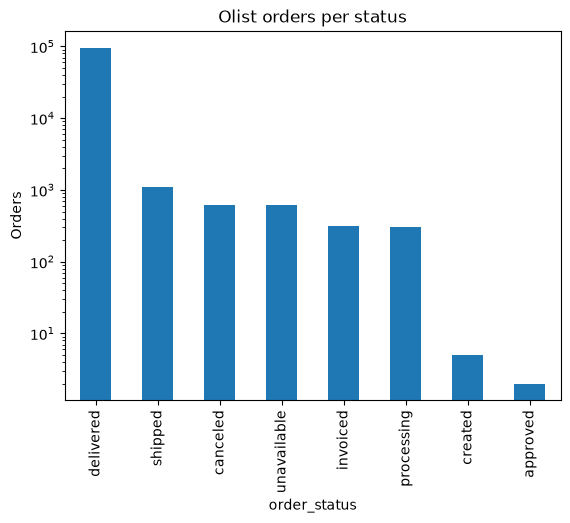

In [34]:
ax = orders["order_status"].value_counts().plot(kind="bar", title="Olist orders per status" ,logy=True)
ax.set_ylabel("Orders")